<div align="center">

# Artificial Neural Networks Project

<img src="https://logoyab.com/wp-content/uploads/2024/08/IUST-University-Logo-1030x1030.png" alt="Logo" width="180">

### Artificial Intelligence
### Multi-Layer Perceptron From Scratch Using NumPy

</div>

---

**Full Name:** Ehsan Abdollahi Nasab

**Student Number:** 403522001

---

In this project, you will build a complete **Multi-Layer Perceptron (MLP)** from scratch using only **NumPy** (following Russell & Norvig's *AIMA*).

Computations are done **matrix/vector-wise**: instead of slow nested `for`-loops over samples, features, or neurons, preprocessing, forward propagation, loss, L2 regularization, backpropagation, and evaluation metrics are all implemented as matrix operations (`@`, outer products, matrix traces, Gram matrices).

The notebook has **three parts**:
1. **Data Understanding & Preprocessing:** Clean and transform the messy `adult_full_merged.csv`, using vectorized encoding/scaling and avoiding data leakage.
2. **MLP for Binary Classification:** Build a 4-layer network from scratch with explicit matrix formulations (bias expansion, inner-product BCE, Frobenius norm via $\text{Tr}(WW^T)$, matrix-multiplied backprop).
3. **Analysis:** Empirically study **Batch vs. Mini-Batch vs. SGD**, **ReLU vs. Sigmoid**, **learning rate ($\eta$)** on the Adult Census Income dataset.

# About the Dataset

### Dataset: Adult Census Income (`adult_full_merged.csv`)

In this project, we use the **Adult Census Income** dataset to predict whether an individual's annual income exceeds 50K USD based on demographic, educational, and occupational features.

- Each **row** represents one sample (an individual).
- Each **column** represents a feature or the target variable.
- The **target variable** is `income`, which has two classes:
  - `>50K`  → annual income greater than 50K USD (`1`)
  - `<=50K` → annual income less than or equal to 50K USD (`0`)

> ⚠️ **Important:** This dataset has been **intentionally prepared** with several data quality issues. Before training any neural network, you must inspect the data and perform the appropriate preprocessing steps.

The goal of Part 1 is to identify and handle data issues and produce a **reliable, clean dataset** for the neural network.

# Part 1 — Data Understanding & Preprocessing
## 1.1 Loading the Dataset

First, import the required libraries and load the dataset. Then take a quick look at its structure, shape, and a few sample rows.

In [77]:
# DO NOT IMPORT ANY OTHER DEEP LEARNING LIBRARY
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from tqdm import tqdm
from copy import deepcopy

%matplotlib inline

# Set random seed for reproducibility
seed = 42
np.random.seed(seed)

# START TODO ################
# Load the dataset from "adult_full_merged.csv"
# Display the shape of the dataset
# Show the first 5 rows
df = pd.read_csv("adult_full_merged.csv")

print(f"Data frame shape: {df.shape}")

display(df.head())
# END TODO ##################

Data frame shape: (52260, 19)


,id,age,favorite_color,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,shoe_size,capital-gain,capital-loss,hours-per-week,native-country,lucky_number,income
0,8825,47.0,green,Self-emp-not-inc,172034,HS-grad,9.0,Married-civ-spouse,Sales,Husband,White,Male,41,0,0,75.0,United-States,94,>50K
1,24481,42.0,red,Self-emp-not-inc,185129,Prof-school,15.0,Married-civ-spouse,Prof-specialty,Husband,White,Male,40,0,1887,40.0,United-States,47,>50K
2,39927,45.0,black,Private,200471,Some-college,10.0,Married-civ-spouse,Sales,Husband,White,Male,35,0,2415,40.0,United-States,98,>50K
3,36520,40.0,red,Private,59916,HS-grad,9.0,Married-civ-spouse,Craft-repair,Husband,White,Male,44,0,0,40.0,United-States,75,<=50K
4,34795,28.0,blue,State-gov,175409,Some-college,10.0,Separated,Adm-clerical,Not-in-family,White,Female,35,0,0,40.0,United-States,23,<=50K


## 1.2 Preprocessing Tasks
> - **Feature selection:** Not all columns are useful. Identify and drop irrelevant or uninformative synthetic columns (`id`, `favorite_color`, `shoe_size`, `lucky_number`).
> - **Standardizing categories:** The same value may appear in different forms (case variants, extra whitespace, abbreviations like `M` or `US`/`USA`, and missing-value markers like `?`, `NA`, `unknown`, `""`). Unify them before checking duplicates and encoding.
> - **Duplicates:** Check for duplicate rows and remove them.
> - **Missing values:** Compute the proportion of missing values per column and impute numerical columns with the median and categorical columns with the mode.
> - **Outliers:** Some numerical values lie outside a reasonable human/census range (e.g., negative or 200-year-old `age`, 300 `hours-per-week`, or `10,000,000` `capital-gain`). Filter them out.
> - **Vectorized Encoding & Train/Test Scaling:** Encode categorical variables (using a **broadcasted outer equality comparison** instead of nested loops) and standardize numerical features using **matrix/vector broadcasting** fit **on the training data only** to prevent data leakage.

### 1.2.1 Feature Selection

In [78]:
# START TODO ################
# Inspect the columns and drop irrelevant ones ('id', 'favorite_color', 'shoe_size', 'lucky_number')
# print(df.shape)

clean_data = df.drop(columns=["id", "favorite_color", "shoe_size", "lucky_number"])
print(f"Shape after feature selection: {clean_data.shape}")

# END TODO ##################

Shape after feature selection: (52260, 15)


### 1.2.2 Standardize Categorical Values

In [79]:
# Inspect unique values to spot inconsistencies

# START TODO ################
# 1. Strip whitespace from string columns and convert to lowercase
# 2. Unify case / synonyms (e.g., Male/male/MALE/M -> 'male'; US/USA/united states -> 'united-states')
# 3. Unify missing-value markers ('?', 'na', 'nan', 'unknown', '') into np.nan

clean_data["sex"] = clean_data["sex"].map(
    lambda sex: "Male" if sex in ["male", "MALE", "M"] else sex
    )

clean_data["native-country"] = clean_data["native-country"].map(
    lambda country: "United-States" if country in ["united states", "US", "USA"] else country
    )

categorical_columns = ["workclass", "education", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]

for column in categorical_columns:
    clean_data[column] = clean_data[column].map(
        lambda value: np.nan if value in ["NA", "unknown", "?", "nan", "na", ""] else value
    )

# END TODO ##################

### 1.2.3 Duplicates & Missing Values

In [80]:
# START TODO ################
# --- Duplicates ---
# 1. Count duplicate rows
# 2. Drop duplicates and reset index
# 3. Display the shape of the dataset after dropping duplicates

clean_data.drop_duplicates(inplace=True)
print(f"number of duplicate rows: {df.shape[0] - clean_data.shape[0]}")

# --- Missing Values ---
# 4. Compute missing-value percentages per column
# 5. Impute numerical columns with the median
# 6. Impute categorical columns with the mode
# 7. Verify that no missing values remain

for column in clean_data.columns:
    if column == "income":
        continue
    if column in categorical_columns:
        df_mode = clean_data[column].mode().iloc[0]
        clean_data[column] = clean_data[column].fillna(df_mode)
    else:
        df_median = clean_data[column].median()
        clean_data[column] = clean_data[column].fillna(df_median)

# END TODO ##################

number of duplicate rows: 2681


### 1.2.4 Outliers
Inspect numerical summaries (`df.describe()`). Notice that `age` has values like `-10` and `200`, `hours-per-week` has `300`, and `capital-gain` has `10,000,000`. Filter the dataset to keep realistic ranges:
* $17 \le \text{age} \le 100$
* $1 \le \text{hours-per-week} \le 100$
* $\text{capital-gain} \le 100,000$

In [81]:
# START TODO ################
# Filter out extreme/impossible outliers in 'age', 'hours-per-week', and 'capital-gain'
print(f"shape before filtering outliers:{clean_data.shape[0]}")
mask = (
    clean_data["age"].between(17, 100) &
    clean_data["hours-per-week"].between(1, 100) &
    (clean_data["capital-gain"] <= 100000)
)
clean_data = clean_data[mask]
print(f"shape after: {clean_data.shape[0]}")
# END TODO ##################

shape before filtering outliers:49579
shape after: 49566


### 1.2.5 Vectorized Encoding, Train/Test Split & Matrix Standardization

Neural networks only operate on numerical vectors and matrices. Here we convert all categorical variables into numerical representations and standardize continuous features.

#### 1. Target Encoding
Convert `income`:
* `<=50k` $\rightarrow 0$
* `>50k` $\rightarrow 1$

#### 2. Ordinal Encoding
Map `education` using its natural hierarchy (`preschool`: 1 up to `doctorate`: 18).

#### 3. Vectorized One-Hot Encoding (Replacing Nested Loops with Outer Broadcasting)
Instead of looping over every unique value of a column `col` to create binary columns one by one, we can use **NumPy outer broadcasting**!
If `v = df[col].to_numpy()[:, None]` is a column vector of shape $(N, 1)$ and `u = df[col].unique()[None, :]` is a row vector of shape $(1, K)$, then the broadcasted equality comparison:
$$B = (v == u)$$
produces the entire $(N, K)$ binary One-Hot matrix in a single vectorized operation!

#### 4. Train/Test Split & Vectorized Z-Score Standardization (No Data Leakage)
Let $X_{\text{train}} \in \mathbb{R}^{I \times m_{\text{train}}}$ and $X_{\text{test}} \in \mathbb{R}^{I \times m_{\text{test}}}$ be our feature matrices where each **column** is a sample and each **row** is a feature.
For the numerical feature rows, we compute the mean column vector $\boldsymbol{\mu} \in \mathbb{R}^{d \times 1}$ and standard deviation column vector $\boldsymbol{\sigma} \in \mathbb{R}^{d \times 1}$ **using only the training set**:
$$\boldsymbol{\mu} = \frac{1}{m_{\text{train}}} X_{\text{train, num}} \mathbf{1}_{m_{\text{train}}}, \qquad \boldsymbol{\sigma} = \sqrt{\frac{1}{m_{\text{train}}} \big(X_{\text{train, num}} - \boldsymbol{\mu} \mathbf{1}_{m_{\text{train}}}^T\big)^{\odot 2} \mathbf{1}_{m_{\text{train}}}}$$
and standardize both training and test sets via broadcasting.

In [82]:
clean_data["education"].unique()

array(['HS-grad', 'Prof-school', 'Some-college', 'Bachelors', '11th',
       'Assoc-acdm', 'Assoc-voc', 'Masters', '10th', 'Doctorate',
       '7th-8th', '12th', '9th', '5th-6th', '1st-4th', 'Preschool'],
      dtype=object)

In [83]:
# --- 1. Target Encoding ---
# START TODO ################
# Convert '<=50k' to 0 and '>50k' to 1
# df["income"] = ...

clean_data["income"] = clean_data["income"].map(
    lambda income: 0 if income == "<=50K" else 1
)

# --- 2. Ordinal Encoding ---
education_order = {
    "Preschool": 1, "1st-4th": 2, "2nd-4th": 3, "3rd-4th": 4, "5th-6th": 5,
    "7th-8th": 6, "9th": 7, "10th": 8, "11th": 9, "12th": 10,
    "HS-grad": 11, "Some-college": 12, "Assoc-voc": 13, "Assoc-acdm": 14,
    "Bachelors": 15, "Masters": 16, "Prof-school": 17, "Doctorate": 18
}
# df["education"] = ...

clean_data["education"] = clean_data["education"].map(education_order)

# --- 3. Vectorized One-Hot Encoding (From Scratch via Broadcasting) ---
nominal_cols = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
num_cols = ["age", "fnlwgt", "education", "education-num", "capital-gain", "capital-loss", "hours-per-week"]

encoded_values = []
encoded_cols = []

for column in nominal_cols:
    vals = clean_data[column].to_numpy().reshape(-1, 1)
    categories = clean_data[column].unique()
    one_hot_matrix = (vals == categories.reshape(1, -1)).astype(np.int64)
    encoded_values.append(one_hot_matrix)
    encoded_cols.extend([f"{column}_{category}" for category in categories])

nominal_part_encoded = pd.DataFrame(
    np.concatenate(encoded_values, axis=1),
    columns=encoded_cols,
    index=clean_data.index
)

clean_data = clean_data.drop(columns=nominal_cols)
clean_data = pd.concat([clean_data, nominal_part_encoded], axis=1)

X = clean_data.drop(columns=["income"]).to_numpy(dtype=float)
y = clean_data["income"].to_numpy(dtype=float).reshape(-1, 1)

# Hint: For each col in nominal_cols, use (vals[:, None] == uniques[None, :]).astype(np.float64)
# Stack numerical features X_num and one-hot features X_ohe into X_all of shape (N, I)

# --- 4. Train/Test Split (80/20) & Standardization (Fit on Train Only) ---
# Split using np.random.permutation(N) with seed=42, transpose to (I, m),
# and standardize the first len(num_cols) rows of x_train and x_test using x_train's mean and std.

permuted_indices = np.random.permutation(clean_data.shape[0])
boundry = int(clean_data.shape[0] * 0.8)
train_indices = permuted_indices[:boundry]
test_indices = permuted_indices[boundry:]

x_train = X[train_indices].T
y_train = y[train_indices].T
x_test = X[test_indices].T
y_test = y[test_indices].T

x_train_numeric = x_train[:len(num_cols), :]
m = x_train.shape[1]
mu = (x_train_numeric @ np.ones((m, 1))) / m

deviation = x_train_numeric - mu @ np.ones((1, m))
variance = (deviation ** 2 @ np.ones((m, 1))) / m
sigma = np.sqrt(variance)

x_train[:len(num_cols), :] = (x_train[:len(num_cols), :] - mu) / sigma
x_test[:len(num_cols), :] = (x_test[:len(num_cols), :] - mu) / sigma

# END TODO ##################

print(f"x_train shape: {x_train.shape}, y_train shape: {y_train.shape}")
print(f"x_test shape:  {x_test.shape},  y_test shape:  {y_test.shape}")
print(f"(Total Input Features, I = {x_train.shape[0]})")

x_train shape: (91, 39652), y_train shape: (1, 39652)
x_test shape:  (91, 9914),  y_test shape:  (1, 9914)
(Total Input Features, I = 91)


In [84]:
# Sample test case for Part 1
assert x_train.shape[0] == x_test.shape[0], "Feature dimension mismatch!"
assert x_train.shape[0] >= 85, "One-hot encoding did not produce the expected number of features!"
assert y_train.shape == (1, x_train.shape[1]), "y_train must have shape (1, m_train)!"
assert np.allclose(np.mean(x_train[:7, :], axis=1), 0.0, atol=1e-6), "Numerical training features must have zero mean!"
assert np.allclose(np.std(x_train[:7, :], axis=1), 1.0, atol=1e-6), "Numerical training features must have unit std!"
print("Part 1 Preprocessing Test Passed ")

Part 1 Preprocessing Test Passed 


---
# Part 2 — Vectorized MLP for Binary Classification

In this part, we build a **4-layer Fully-Connected Neural Network (MLP)** to predict whether an individual's income exceeds `$50K` (`1`) or not (`0`).

### 2.1 MLP Architecture & Matrix Dimensions
**Architecture:** `Input (X) -> [FC1 -> ReLU] -> [FC2 -> ReLU] -> [FC3 -> ReLU] -> [FC4 -> Sigmoid] -> Output (A4)`

For a batch of $m$ examples arranged as columns of $X \in \mathbb{R}^{I \times m}$:
* **Layer 0 (Input):** $A^{[0]} = X \in \mathbb{R}^{I \times m}$
* **Layer 1 (Hidden 1):** $W^{[1]} \in \mathbb{R}^{H_1 \times I}, \quad b^{[1]} \in \mathbb{R}^{H_1 \times 1} \quad (H_1 = 64)$
* **Layer 2 (Hidden 2):** $W^{[2]} \in \mathbb{R}^{H_2 \times H_1}, \quad b^{[2]} \in \mathbb{R}^{H_2 \times 1} \quad (H_2 = 32)$
* **Layer 3 (Hidden 3):** $W^{[3]} \in \mathbb{R}^{H_3 \times H_2}, \quad b^{[3]} \in \mathbb{R}^{H_3 \times 1} \quad (H_3 = 16)$
* **Layer 4 (Output):** $W^{[4]} \in \mathbb{R}^{O \times H_3}, \quad b^{[4]} \in \mathbb{R}^{O \times 1} \quad (O = 1)$

## 2.2 Helper: Parameter Initialization (He Initialization)

**NOTE: This function is already implemented for you.**

To prevent vanishing or exploding gradients in ReLU networks, we initialize weights using **He Initialization**:
$$W^{[l]} \sim \mathcal{N}\left(0, \frac{2}{n^{[l-1]}}\right), \qquad b^{[l]} = \mathbf{0}$$

In [85]:
def Initialization(I, H1, H2, H3, O):
    '''
    Initializes weights using He Initialization (optimized for ReLU).

    Inputs:
        I, H1, H2, H3, O: Number of neurons in each layer.

    Returns:
        List of parameters: [W1, b1, W2, b2, W3, b3, W4, b4]
    '''
    np.random.seed(42)

    scale1 = np.sqrt(2.0 / I)
    scale2 = np.sqrt(2.0 / H1)
    scale3 = np.sqrt(2.0 / H2)
    scale4 = np.sqrt(2.0 / H3)

    W1 = np.random.randn(H1, I) * scale1
    b1 = np.zeros((H1, 1))

    W2 = np.random.randn(H2, H1) * scale2
    b2 = np.zeros((H2, 1))

    W3 = np.random.randn(H3, H2) * scale3
    b3 = np.zeros((H3, 1))

    W4 = np.random.randn(O, H3) * scale4
    b4 = np.zeros((O, 1))

    return [W1, b1, W2, b2, W3, b3, W4, b4]

In [86]:
# Sample test case
np.random.seed(seed)
params_test = Initialization(x_train.shape[0], 64, 32, 16, 1)
assert len(params_test) == 8
assert params_test[0].shape == (64, x_train.shape[0])
assert params_test[1].shape == (64, 1)
assert params_test[6].shape == (1, 16)
print("Sample Test passed.")

Sample Test passed.


## 2.3 Task: Element-wise Activation Functions (ReLU & Sigmoid)

Implement the **ReLU** activation function and its derivative (for hidden layers), as well as the **Sigmoid** activation function and its derivative (for the binary classification output layer and Part 3 experiments).

$$\text{ReLU}(Z) = \max(0, Z), \qquad \text{dReLU}(Z) = \mathbb{I}(Z > 0)$$

$$\sigma(Z) = \frac{1}{1 + e^{-Z}}, \qquad \sigma'(Z) = \sigma(Z) \odot \big(1 - \sigma(Z)\big)$$

> **Tip:** Clip $Z$ to $[-500, 500]$ inside `sigmoid(Z)` using `np.clip` to prevent numerical overflow in `np.exp(-Z)`.

In [87]:
def relu(z):
    # START TODO ################ (approx. 1 line)
    return np.maximum(0, z)
    # END TODO ##################

def drelu(z:np.ndarray):
    # START TODO ################ (approx. 1 line)
    return (z > 0).astype(float)
    # END TODO ##################

def sigmoid(z):
    # START TODO ################ (approx. 2 lines)
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))
    # END TODO ##################

def dsigmoid(z):
    # START TODO ################ (approx. 2 lines)
    s = sigmoid(z)
    return s * (1 - s)
    # END TODO ##################

In [88]:
# Sample test case
z_sample = np.array([[3.0, -4.0], [0.0, -0.5]])
assert np.allclose(relu(z_sample), np.array([[3.0, 0.0], [0.0, 0.0]]))
assert np.allclose(drelu(z_sample), np.array([[1.0, 0.0], [0.0, 0.0]]))
assert np.allclose(sigmoid(np.array([[0.0]])), np.array([[0.5]]))
assert np.allclose(dsigmoid(np.array([[0.0]])), np.array([[0.25]]))
print("Sample Test passed.")

Sample Test passed.


## 2.4 Task: Practical Linear Algebra — Loops vs. Matrix Multiplication & Forward Pass

### Why Linear Algebra Matters in Neural Networks
Suppose Layer $l$ has $n_{\text{in}}$ inputs and $n_{\text{out}}$ neurons, and we process a batch of $m$ examples.
A naive implementation uses **three nested loops** (over samples $k=1\dots m$, output neurons $i=1\dots n_{\text{out}}$, and input features $j=1\dots n_{\text{in}}$):
$$Z^{[l]}_{i, k} = \sum_{j=1}^{n_{\text{in}}} W^{[l]}_{i, j} A^{[l-1]}_{j, k} + b^{[l]}_{i, 1}$$

In **Practical Linear Algebra**, we express the entire layer's pre-activation across all $m$ samples simultaneously using **matrix multiplication** and an **outer product** with a vector of ones $\mathbf{1}_m \in \mathbb{R}^{m \times 1}$:
$$Z^{[l]} = W^{[l]} A^{[l-1]} + b^{[l]} \mathbf{1}_m^T$$
where:
* $W^{[l]} A^{[l-1]}$ is the matrix product `W @ A_prev` of shape $(n_{\text{out}}, m)$.
* $b^{[l]} \mathbf{1}_m^T$ is the rank-1 outer product `b @ np.ones((1, m))` of shape $(n_{\text{out}}, m)$, which mathematically represents bias broadcasting!

**Your Task:**
1. Implement `affine_forward_naive(A_prev, W, b)` using explicit loops (to observe its speed on a small batch) and `affine_forward_matrix(A_prev, W, b)` using pure matrix multiplication `W @ A_prev + b @ np.ones((1, m))`.
2. Implement `feed_forward(X, params)` for our 4-layer network using `affine_forward_matrix`:
   * Layers 1, 2, 3 use `relu`.
   * Layer 4 (Output) uses `sigmoid`.

In [89]:
def affine_forward_naive(A_prev, W, b):
    '''
    Naive loop-based affine transformation Z = W A_prev + b (for timing comparison only).
    '''
    n_out, n_in = W.shape
    m = A_prev.shape[1]
    Z = np.zeros((n_out, m))
    for k in range(m):
        for i in range(n_out):
            s = 0.0
            for j in range(n_in):
                s += W[i, j] * A_prev[j, k]
            Z[i, k] = s + b[i, 0]
    return Z

def affine_forward_matrix(A_prev, W, b):
    '''
    Vectorized linear algebra affine transformation: Z = W @ A_prev + b @ 1_m^T
    Inputs:
      - A_prev: Activation matrix from previous layer, shape (n_in, m)
      - W: Weight matrix, shape (n_out, n_in)
      - b: Bias column vector, shape (n_out, 1)
    Output:
      - Z: Pre-activation matrix, shape (n_out, m)
    '''
    m = A_prev.shape[1]
    # START TODO ################ (approx. 2 lines)
    # Use matrix multiplication (@) and an outer product with np.ones((1, m))
    Z = W @ A_prev + b @ np.ones((1, m))
    # END TODO ##################
    return Z

def feed_forward(X, params):
    '''
    Inputs:
      - X: Input data matrix of shape (I, m)
      - params: List of parameters [W1, b1, W2, b2, W3, b3, W4, b4]
    Outputs:
      - y_out: Predicted probabilities (A4), shape (1, m)
      - cache: List containing [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    '''
    W1, b1, W2, b2, W3, b3, W4, b4 = params
    A0 = X

    # START TODO ################ (approx. 9 lines)
    # Compute Z1, A1, Z2, A2, Z3, A3 (with relu) and Z4, A4 (with sigmoid)
    # Store [Z1, A1, Z2, A2, Z3, A3, Z4, A4] in cache
    Z1 = affine_forward_matrix(A0, W1, b1)
    A1 = relu(Z1)
    Z2 = affine_forward_matrix(A1, W2, b2)
    A2 = relu(Z2)
    Z3 = affine_forward_matrix(A2, W3, b3)
    A3 = relu(Z3)
    Z4 = affine_forward_matrix(A3, W4, b4)
    A4 = sigmoid(Z4)
    cache = [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
    # END TODO ##################

    y_out = A4
    return y_out, cache

In [90]:
# Sample test case & Linear Algebra Speedup Benchmark
np.random.seed(seed)
I_dim, H1_dim, H2_dim, H3_dim, O_dim, m_bench = x_train.shape[0], 64, 32, 16, 1, 200
params_bench = Initialization(I_dim, H1_dim, H2_dim, H3_dim, O_dim)
X_bench = x_train[:, :m_bench]

t0 = time.perf_counter()
Z_naive = affine_forward_naive(X_bench, params_bench[0], params_bench[1])
t_naive = time.perf_counter() - t0

t0 = time.perf_counter()
Z_matrix = affine_forward_matrix(X_bench, params_bench[0], params_bench[1])
t_matrix = time.perf_counter() - t0

assert np.allclose(Z_naive, Z_matrix), "Matrix affine forward does not match naive loop!"
print(f"Naive 3-Loop Time (200 samples): {t_naive*1000:.2f} ms")
print(f"Matrix Product Time (200 samples): {t_matrix*1000:.3f} ms (Speedup: {t_naive/max(t_matrix, 1e-9):.1f}x!)")

y_forward, cache = feed_forward(X_bench, params_bench)
assert y_forward.shape == (O_dim, m_bench)
assert len(cache) == 8
assert cache[0].shape == (H1_dim, m_bench)
assert cache[7].shape == (O_dim, m_bench)
print("Sample Test passed.")

Naive 3-Loop Time (200 samples): 370.12 ms
Matrix Product Time (200 samples): 0.494 ms (Speedup: 749.5x!)
Sample Test passed.


## 2.5 Task: Vectorized Binary Cross-Entropy Loss (Inner Product Formulation)

For binary classification, the Binary Cross-Entropy (BCE) loss over $m$ samples is:
$$L = -\frac{1}{m} \sum_{i=1}^{m} \Big( y_d^{(i)} \log(\hat{y}^{(i)}) + (1 - y_d^{(i)}) \log(1 - \hat{y}^{(i)}) \Big)$$

**Practical Linear Algebra Formulation:**
Since $y_d \in \mathbb{R}^{1 \times m}$ and $\hat{y} \in \mathbb{R}^{1 \times m}$ are row vectors, a summation of element-wise products $\sum_{i=1}^m u_i v_i$ is simply the **vector dot product (inner product)** $u v^T$!
Therefore, we can compute the entire sum without `np.sum` or loops by using matrix multiplication (`@`):
$$L = -\frac{1}{m} \Big( y_d \big(\log(\hat{y})\big)^T + (1 - y_d) \big(\log(1 - \hat{y})\big)^T \Big)$$

> **Tip:** Clip `y_pred` to $[10^{-15}, 1 - 10^{-15}]$ before taking `np.log`, and use `.item()` (or `[0, 0]`) to return a Python float scalar.

In [91]:
def loss_compute(y_pred, yd):
    '''
    Computes Binary Cross-Entropy loss using vector inner products (@).
    Inputs:
      - y_pred: (1, m) numpy array of predicted probabilities (A4)
      - yd: (1, m) numpy array of true binary labels (0 or 1)
    Output:
      - loss: Scalar float BCE loss
    '''
    m = yd.shape[1]
    eps = 1e-15
    y_pred_clipped = np.clip(y_pred, eps, 1.0 - eps)

    # START TODO ################ (approx. 3 lines)
    # Compute BCE loss using dot products (@) between row vectors and transposed log vectors
    loss = - (yd @ np.log(y_pred_clipped).T + (1 - yd) @ np.log(1 - y_pred_clipped).T) / m
    # END TODO ##################
    return loss[0, 0]

In [92]:
# Sample test case
y_p_sample = np.array([[0.9, 0.2, 0.8]])
y_d_sample = np.array([[1.0, 0.0, 1.0]])
sample_loss = loss_compute(y_p_sample, y_d_sample)
assert np.allclose(sample_loss, 0.18388253942874858)
print("Sample Test passed.")

Sample Test passed.


## 2.6 Task: L2 Regularization via Matrix Trace ($\|W\|_F^2 = \text{Tr}(W W^T)$)

To prevent overfitting, we add an L2 penalty proportional to the squared **Frobenius norm** of each weight matrix:
$$L_{\text{reg}} = \frac{\lambda}{2m} \sum_{l=1}^{4} \|W^{[l]}\|_F^2$$

**Practical Linear Algebra Identity:**
For any matrix $W \in \mathbb{R}^{r \times c}$, the sum of squares of all its entries equals the **trace of its Gram matrix** $W W^T$:
$$\|W\|_F^2 = \sum_{i=1}^{r} \sum_{j=1}^{c} W_{i,j}^2 = \text{Tr}\big(W W^T\big)$$

**Your Task:** Implement `regularization_L2` using `np.trace(W @ W.T)` for each weight matrix $W^{[1]}, W^{[2]}, W^{[3]}, W^{[4]}$.

In [93]:
def regularization_L2(lmbda, W1, W2, W3, W4, m):
    '''
    Computes L2 regularization loss using the matrix trace identity ||W||_F^2 = Tr(W @ W.T).
    '''
    # START TODO ################ (approx. 3 lines)
    # Compute ||W||_F^2 using np.trace(W @ W.T) for W1, W2, W3, W4
    weightes = [np.asarray(mtrx) for mtrx in [W1, W2, W3, W4]]
    sum_square = 0
    for w_mtrx in weightes:
        sum_square += np.trace(w_mtrx @ w_mtrx.T)

    reg_loss = (lmbda/(2*m)) * sum_square
    # END TODO ##################
    return float(reg_loss)

In [94]:
# Sample test case
w1_t = np.array([[1.0, 2.0], [3.0, 4.0]]) # sum of squares = 30
w2_t = np.ones((2, 2))                    # sum of squares = 4
w3_t, w4_t = w2_t.copy(), w2_t.copy()     # total sum of squares = 30 + 4 + 4 + 4 = 42
assert np.allclose(regularization_L2(0.1, w1_t, w2_t, w3_t, w4_t, 2), 0.1 * 42 / 4.0)
print("Sample Test passed.")

Sample Test passed.


## 2.7 Task: Vectorized Backpropagation

Now implement the backward pass for our 4-layer binary classification network using **pure matrix algebra**.

**Key Matrix Formulas:**
1. **Output Layer ($l = 4$, Sigmoid + BCE Loss):**
   By the chain rule, the derivative of Binary Cross-Entropy with respect to the pre-activation $Z^{[4]}$ simplifies to:
   $$dZ^{[4]} = \frac{\partial L}{\partial Z^{[4]}} = \frac{1}{m}\big(A^{[4]} - Y\big) \in \mathbb{R}^{1 \times m}$$

2. **For any Layer $l \in \{4, 3, 2, 1\}$:**
   * **Weight Gradient (Sum of outer products across the batch via matrix multiplication):**
     $$dW^{[l]} = dZ^{[l]} \big(A^{[l-1]}\big)^T + \frac{\lambda}{m} W^{[l]} \in \mathbb{R}^{n^{[l]} \times n^{[l-1]}}$$
   * **Bias Gradient (Matrix-vector product with a column vector of ones $\mathbf{1}_m \in \mathbb{R}^{m \times 1}$):**
     Instead of calling `np.sum(dZ, axis=1, keepdims=True)`, notice that summing the columns of $dZ^{[l]}$ is identical to multiplying $dZ^{[l]}$ by $\mathbf{1}_m = \text{np.ones}((m, 1))$:
     $$db^{[l]} = dZ^{[l]} \mathbf{1}_m \in \mathbb{R}^{n^{[l]} \times 1}$$
   * **Propagate to Previous Layer ($l > 1$):**
     $$dA^{[l-1]} = \big(W^{[l]}\big)^T dZ^{[l]}, \qquad dZ^{[l-1]} = dA^{[l-1]} \odot g'\big(Z^{[l-1]}\big)$$
     where $g'$ is `drelu`.

In [95]:
def Backpropagation(X, yd, cache, parameters, lmbda):
    '''
    Performs the vectorized backward pass for the 4-layer binary classification MLP.

    Inputs:
      - X: Input features (I, m)
      - yd: True binary labels (1, m)
      - cache: List from feed_forward [Z1, A1, Z2, A2, Z3, A3, Z4, A4]
      - parameters: List of parameters [W1, b1, W2, b2, W3, b3, W4, b4]
      - lmbda: L2 regularization parameter

    Outputs:
      - grads: Dictionary of gradients {"dW1": dW1, "db1": db1, ..., "dW4": dW4, "db4": db4}
    '''
    m = X.shape[1]
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters
    Z1, A1, Z2, A2, Z3, A3, Z4, A4 = cache
    ones_m = np.ones((m, 1))
    grads = {}

    # START TODO ################ (approx. 16 lines)
    # Compute dZ4, dW4, db4, then backpropagate through layers 3, 2, 1 using @ and ones_m
    dZ4 = (A4 - yd) / m
    dW4 = dZ4 @ A3.T + (lmbda/m) * W4
    db4 = dZ4 @ ones_m

    dA3 = W4.T @ dZ4
    dZ3 = dA3 * drelu(Z3)
    dW3 = dZ3 @ A2.T + (lmbda/m) * W3
    db3 = dZ3 @ ones_m
    
    dA2 = W3.T @ dZ3
    dZ2 = dA2 * drelu(Z2)
    dW2 = dZ2 @ A1.T + (lmbda/m) * W2
    db2 = dZ2 @ ones_m

    dA1 = W2.T @ dZ2
    dZ1 = dA1 * drelu(Z1)
    dW1 = dZ1 @ X.T + (lmbda/m) * W1
    db1 = dZ1 @ ones_m

    grads = {
        "db1": db1,
        "dW1": dW1,
        "db2": db2,
        "dW2": dW2,
        "db3": db3,
        "dW3": dW3,
        "db4": db4,
        "dW4": dW4,
    }
    # END TODO ##################

    return grads

In [96]:
# Sample test case
np.random.seed(seed)
I_t, H1_t, H2_t, H3_t, O_t, m_t = x_train.shape[0], 64, 32, 16, 1, 100
params_t = Initialization(I_t, H1_t, H2_t, H3_t, O_t)
X_t = x_train[:, :m_t]
Y_t = y_train[:, :m_t]
y_f_t, cache_t = feed_forward(X_t, params_t)
grads_t = Backpropagation(X_t, Y_t, cache_t, params_t, lmbda=0.1)

assert grads_t["dW1"].shape == (H1_t, I_t)
assert grads_t["db1"].shape == (H1_t, 1)
assert grads_t["dW4"].shape == (O_t, H3_t)
assert grads_t["db4"].shape == (O_t, 1)
print("Sample Test passed.")

Sample Test passed.


## 2.8 Task: Training the Model (Batch Gradient Descent)

Combine your forward pass, loss computation, L2 regularization, and backpropagation to train the MLP on the Adult Census Income dataset.

**Steps for each iteration:**
1. Perform `feed_forward(X, parameters)` to get `y_pred` and `cache`.
2. Compute `bce_loss = loss_compute(y_pred, yd)` and `reg_loss = regularization_L2(lmbda, W1, W2, W3, W4, m)`.
3. Record `total_loss = bce_loss + reg_loss` in `losses`.
4. Compute gradients via `Backpropagation(X, yd, cache, parameters, lmbda)`.
5. Update all parameters:
   $$W^{[l]} \leftarrow W^{[l]} - \eta \, dW^{[l]}, \qquad b^{[l]} \leftarrow b^{[l]} - \eta \, db^{[l]}$$

In [97]:
def compute_accuracy(y_pred, yd):
    '''Vectorized binary accuracy calculation.'''
    preds = (y_pred >= 0.5).astype(float)
    return float(np.mean(preds == yd))

def training_clf(X, yd, parameters, eta=0.1, num_iters=400, lmbda=0.01):
    '''
    Trains the 4-layer binary classification MLP using Batch Gradient Descent.
    '''
    losses = []
    accuracies = []
    m = X.shape[1]

    W1, b1, W2, b2, W3, b3, W4, b4 = deepcopy(parameters)

    for i in tqdm(range(num_iters)):
        # START TODO ################ (approx. 16 lines)
        # 1. Forward pass
        # 2. Compute BCE loss + L2 reg_loss and append to losses
        # 3. Backpropagation
        # 4. Update W1..W4 and b1..b4
        y_pred, cache = feed_forward(X, [W1, b1, W2, b2, W3, b3, W4, b4])
        bce_loss = loss_compute(y_pred, yd)
        reg_loss = regularization_L2(lmbda, W1, W2, W3, W4, m)
        losses.append(bce_loss + reg_loss)
        grads = Backpropagation(X, yd, cache, parameters, lmbda)

        W1 = W1 - eta * grads["dW1"]
        b1 = b1 - eta * grads["db1"]
        
        W2 = W2 - eta * grads["dW2"]
        b2 = b2 - eta * grads["db2"]
        
        W3 = W3 - eta * grads["dW3"]
        b3 = b3 - eta * grads["db3"]

        W4 = W4 - eta * grads["dW4"]
        b4 = b4 - eta * grads["db4"]
        # END TODO ##################

        if i % 20 == 0 or i == num_iters - 1:
            accuracies.append(compute_accuracy(y_pred, yd))

    parameters_final = [W1, b1, W2, b2, W3, b3, W4, b4]
    return losses, accuracies, parameters_final

100%|██████████| 300/300 [00:13<00:00, 22.91it/s]


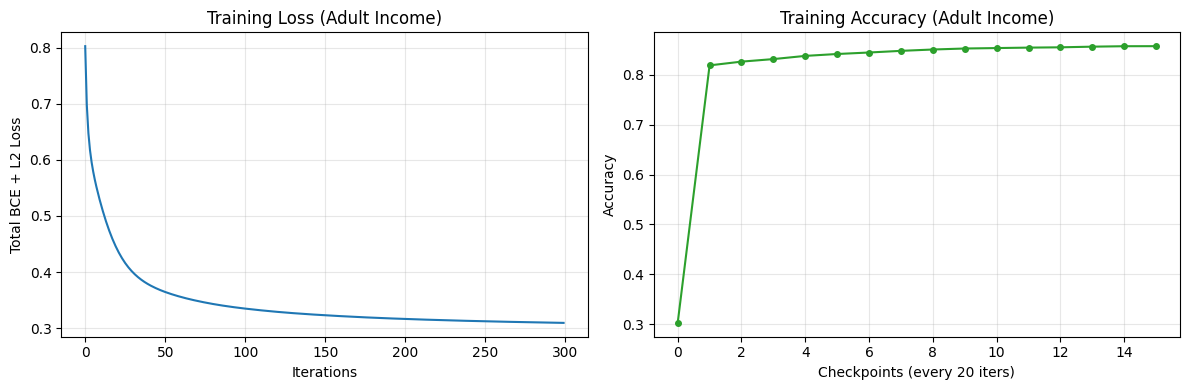

In [98]:
# Train the MLP on our preprocessed Adult Census Income training set
I_clf = x_train.shape[0]
O_clf = y_train.shape[0]
H1, H2, H3 = 64, 32, 16

np.random.seed(seed)
init_params_clf = Initialization(I_clf, H1, H2, H3, O_clf)

# Use a 10,000-sample training subset for fast interactive execution
m_train_sub = 10000
X_sub_train = x_train[:, :m_train_sub]
y_sub_train = y_train[:, :m_train_sub]

losses_clf, accuracies_clf, params_clf = training_clf(
    X_sub_train,
    y_sub_train,
    init_params_clf,
    eta=0.15,
    num_iters=300,
    lmbda=0.01
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(losses_clf, color='tab:blue')
axes[0].set_title("Training Loss (Adult Income)")
axes[0].set_xlabel("Iterations")
axes[0].set_ylabel("Total BCE + L2 Loss")
axes[0].grid(True, alpha=0.3)

axes[1].plot(accuracies_clf, color='tab:green', marker='o', markersize=4)
axes[1].set_title("Training Accuracy (Adult Income)")
axes[1].set_xlabel("Checkpoints (every 20 iters)")
axes[1].set_ylabel("Accuracy")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [100]:
# Evaluate on the held-out Test Set
assert losses_clf[-1] < losses_clf[0], "Loss should decrease during training!"
y_pred_test, _ = feed_forward(x_test, params_clf)
test_acc = compute_accuracy(y_pred_test, y_test)
print(f"Final Test Accuracy (Adult Census Income): {test_acc * 100:.2f}%")
assert test_acc > 0.82, "Test accuracy should be above 82%!"
print("Sample Test passed.")

Final Test Accuracy (Adult Census Income): 84.83%
Sample Test passed.


---
# Part 3 — Analysis

In this part, you will use your Adult Census Income MLP from Part 2 to conduct three analytical experiments and answer the corresponding conceptual questions.

## 3.1 Analysis: Batch GD vs. Mini-Batch GD vs. Stochastic Gradient Descent (SGD)

In `training_clf`, we used **Batch Gradient Descent**, which multiplies the entire matrix $X \in \mathbb{R}^{I \times m}$ at once.
* **Stochastic Gradient Descent (SGD)** updates weights one sample at a time ($m=1$, matrix-vector products). While it makes many parameter updates per epoch, it loses hardware BLAS matrix-matrix parallelism and has high gradient variance.
* **Mini-Batch Gradient Descent** slices $X$ into sub-matrices $X_{\text{batch}} \in \mathbb{R}^{I \times B}$ (e.g., $B = 128$), striking the ideal balance between **fast matrix-matrix multiplication** and **frequent stochastic updates**!

**Your Task:**
1. Implement `training_clf_minibatch(X, yd, parameters, eta, num_epochs, batch_size, lmbda)`.Note that setting `batch_size=1` gives pure **SGD**, `batch_size=128` gives **Mini-Batch GD**, and `batch_size=m` gives **Batch GD**!
2. Run all three on the first `2000` training samples for `10` epochs and compare their **wall-clock execution time** and **loss convergence**.

In [ ]:
def training_clf_minibatch(X, yd, parameters, eta=0.05, num_epochs=10, batch_size=128, lmbda=0.01):
    '''
    Trains the 4-layer MLP using Mini-Batch Gradient Descent (or SGD when batch_size=1).
    '''
    epoch_losses = []
    m = X.shape[1]
    W1, b1, W2, b2, W3, b3, W4, b4 = deepcopy(parameters)

    for epoch in range(num_epochs):
        permutation = np.random.permutation(m)
        X_shuffled = X[:, permutation]
        y_shuffled = yd[:, permutation]

        epoch_loss_weighted = 0.0

        for start_idx in range(0, m, batch_size):
            end_idx = min(start_idx + batch_size, m)
            b_size = end_idx - start_idx
            X_batch = X_shuffled[:, start_idx:end_idx]
            y_batch = y_shuffled[:, start_idx:end_idx]

            # START TODO ################ (approx. 14 lines)
            # Perform forward pass, accumulate weighted batch_loss * b_size, backprop, and update weights
            pass
            # END TODO ##################

        epoch_losses.append(epoch_loss_weighted / m)

    parameters_final = [W1, b1, W2, b2, W3, b3, W4, b4]
    return epoch_losses, parameters_final

In [ ]:
# Compare Batch GD (B=2000), Mini-Batch GD (B=128), and SGD (B=1) over 10 epochs
m_exp = 2000
X_exp = x_train[:, :m_exp]
y_exp = y_train[:, :m_exp]
epochs_exp = 10

np.random.seed(seed)
t0 = time.perf_counter()
losses_bgd, _ = training_clf_minibatch(X_exp, y_exp, init_params_clf, eta=0.05, num_epochs=epochs_exp, batch_size=m_exp, lmbda=0.01)
t_bgd = time.perf_counter() - t0

np.random.seed(seed)
t0 = time.perf_counter()
losses_mbgd, _ = training_clf_minibatch(X_exp, y_exp, init_params_clf, eta=0.05, num_epochs=epochs_exp, batch_size=128, lmbda=0.01)
t_mbgd = time.perf_counter() - t0

np.random.seed(seed)
t0 = time.perf_counter()
losses_sgd, _ = training_clf_minibatch(X_exp, y_exp, init_params_clf, eta=0.01, num_epochs=epochs_exp, batch_size=1, lmbda=0.01)
t_sgd = time.perf_counter() - t0

print(f"Batch GD (B=2000) Time:     {t_bgd:.3f} s | Final Loss: {losses_bgd[-1]:.4f}")
print(f"Mini-Batch GD (B=128) Time: {t_mbgd:.3f} s | Final Loss: {losses_mbgd[-1]:.4f}")
print(f"Pure SGD (B=1) Time:        {t_sgd:.3f} s | Final Loss: {losses_sgd[-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs_exp + 1), losses_bgd, marker='o', label=f'Batch GD (B=2000, {t_bgd:.2f}s)')
plt.plot(range(1, epochs_exp + 1), losses_mbgd, marker='s', label=f'Mini-Batch GD (B=128, {t_mbgd:.2f}s)')
plt.plot(range(1, epochs_exp + 1), losses_sgd, marker='^', label=f'SGD (B=1, {t_sgd:.2f}s)')
plt.xlabel("Epochs")
plt.ylabel("Average Epoch Loss")
plt.title("Analysis 3.1: Batch GD vs. Mini-Batch GD vs. SGD")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3.1 Analysis (Written)

*TODO: Write your analysis here. Compare the three methods in terms of (1) convergence speed per epoch, (2) wall-clock time per epoch (why is matrix-matrix multiplication in Mini-Batch GD so much faster than 2,000 single-vector calls in SGD?), and (3) gradient noise.*

## 3.2 Analysis: Hidden Activation Functions (ReLU vs. Sigmoid)

In deep networks, using `sigmoid` in hidden layers often leads to the **Vanishing Gradient** problem because the maximum derivative of the sigmoid function is $\max_z \sigma'(z) = 0.25$. When multiplying Jacobians backward across multiple layers:
$$dZ^{[l]} = \big((W^{[l+1]})^T dZ^{[l+1]}\big) \odot \sigma'(Z^{[l]})$$
the gradient norm shrinks exponentially toward earlier layers ($0.25^3 \approx 0.0156$).

**Your Task:**
1. Implement `feed_forward_flexible`, `Backpropagation_flexible`, and `training_flexible` that accept `hidden_activation='relu'` or `'sigmoid'` for Hidden Layers 1–3 (Layer 4 always uses `sigmoid` for binary probability output).
2. Train two models for `300` iterations and compare their loss curves.

In [ ]:
def feed_forward_flexible(X, params, hidden_activation='relu'):
    '''
    Forward pass with selectable hidden activation ('relu' or 'sigmoid') for Layers 1-3.
    Layer 4 (Output) is always sigmoid.
    '''
    W1, b1, W2, b2, W3, b3, W4, b4 = params
    g = relu if hidden_activation == 'relu' else sigmoid

    # START TODO ################ (approx. 9 lines)
    pass
    # END TODO ##################
    return A4, cache

def Backpropagation_flexible(X, yd, cache, parameters, lmbda, hidden_activation='relu'):
    '''
    Backward pass with selectable hidden activation derivative ('relu' or 'sigmoid').
    '''
    dg = drelu if hidden_activation == 'relu' else dsigmoid
    m = X.shape[1]
    W1, b1, W2, b2, W3, b3, W4, b4 = parameters
    Z1, A1, Z2, A2, Z3, A3, Z4, A4 = cache
    ones_m = np.ones((m, 1))

    # START TODO ################ (approx. 16 lines)
    pass
    # END TODO ##################
    return grads

def training_flexible(X, yd, parameters, eta=0.15, num_iters=300, lmbda=0.01, hidden_activation='relu'):
    losses = []
    m = X.shape[1]
    W1, b1, W2, b2, W3, b3, W4, b4 = deepcopy(parameters)

    for i in tqdm(range(num_iters)):
        # START TODO ################ (approx. 12 lines)
        pass
        # END TODO ##################

    return losses, [W1, b1, W2, b2, W3, b3, W4, b4]

In [ ]:
print("Running Model with ReLU Hidden Layers...")
losses_relu, params_relu = training_flexible(X_sub_train, y_sub_train, init_params_clf, eta=0.15, num_iters=300, lmbda=0.01, hidden_activation='relu')

print("Running Model with Sigmoid Hidden Layers...")
losses_sigmoid, params_sigmoid = training_flexible(X_sub_train, y_sub_train, init_params_clf, eta=0.15, num_iters=300, lmbda=0.01, hidden_activation='sigmoid')

plt.figure(figsize=(8, 5))
plt.plot(losses_relu, label='ReLU Hidden Activations')
plt.plot(losses_sigmoid, label='Sigmoid Hidden Activations')
plt.xlabel("Iterations")
plt.ylabel("Total Loss")
plt.title("Analysis 3.2: ReLU vs. Sigmoid in Hidden Layers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3.2 Analysis (Written)

*TODO: Write your analysis here. Compare the two loss curves. Which activation function converged faster? Explain the vanishing gradient problem in terms of the derivative $\sigma'(z) \le 0.25$ across multiple matrix multiplications.*

## 3.3 Analysis: Learning Rate ($\eta$) Dynamics

The learning rate $\eta$ controls the step size along the negative gradient direction.
Run `training_clf` on `X_sub_train` for `150` iterations with three learning rates:
* **High:** $\eta = 2.5$
* **Medium (Baseline):** $\eta = 0.15$
* **Low:** $\eta = 0.001$

In [ ]:
print("Running LR = 2.5 (High)...")
losses_lr_high, _, _ = training_clf(X_sub_train, y_sub_train, init_params_clf, eta=2.5, num_iters=150, lmbda=0.01)

print("Running LR = 0.15 (Medium)...")
losses_lr_med, _, _ = training_clf(X_sub_train, y_sub_train, init_params_clf, eta=0.15, num_iters=150, lmbda=0.01)

print("Running LR = 0.001 (Low)...")
losses_lr_low, _, _ = training_clf(X_sub_train, y_sub_train, init_params_clf, eta=0.001, num_iters=150, lmbda=0.01)

plt.figure(figsize=(8, 5))
plt.plot(losses_lr_high, label='LR = 2.5 (High)', alpha=0.85)
plt.plot(losses_lr_med, label='LR = 0.15 (Medium)', linewidth=2)
plt.plot(losses_lr_low, label='LR = 0.001 (Low)', linewidth=2)
plt.xlabel("Iterations")
plt.ylabel("Total Loss")
plt.title("Analysis 3.3: Learning Rate Comparison")
plt.ylim(0.25, 1.5)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 3.3 Analysis (Written)

*TODO: Write your analysis here. Describe the behavior of the high, medium, and low learning rate curves and relate them to overshooting and slow convergence.*